# Evaluation summary

The retrieval algorithm in this app (QASA: query-aware spreading activation in Cypher) was
evaluated at scale in the research project. The original notebooks and their raw per-question
results are archived in [`research/`](research/) (outputs preserved; they ran against Gemini
2.5 Flash + `text-embedding-004` and graphs of 31k / 56k entities, so they are not re-run here).

This notebook only **reads those CSVs** and summarizes them:

1. ablation study (n=500 per dataset): what each component contributes;
2. accuracy vs prompt-token cost;
3. paired significance of the query-aware gate on the full n=1000 split;
4. failure analysis of the default configuration;
5. a small local run of the app itself (qwen3.5:4b via Ollama), if `results/local-eval.csv` exists.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESEARCH = Path("research")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Chart chrome + categorical slots from the dataviz reference palette (light mode).
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK_2, "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})

DATASETS = {"musique": "MuSiQue", "2wiki": "2WikiMultiHopQA"}
LABELS = {
    "steps-3": "QASA default (3 hops, decay 0.7)",
    "no-query-aware": "Uniform spreading (no query gate)",
    "naive-vector": "Naive vector search (no graph)",
    "steps-1": "1 hop", "steps-2": "2 hops", "steps-4": "4 hops",
    "decay-0.3": "decay 0.3", "decay-0.5": "decay 0.5",
    "decay-0.9": "decay 0.9", "decay-1.0": "decay 1.0",
}
ROLE_COLOR = {"steps-3": BLUE, "no-query-aware": ORANGE, "naive-vector": AQUA}

def load_ablation(dataset: str) -> pd.DataFrame:
    rows = []
    for csv in sorted((RESEARCH / f"ablation-results-{dataset}").glob("*.csv")):
        if csv.stem == "decay-0.7":  # identical config to steps-3 (kept as a stochasticity check)
            continue
        df = pd.read_csv(csv)
        rows.append({
            "config": csv.stem, "n": len(df), "EM": df.em.mean(), "F1": df.f1.mean(),
            "prompt_tokens": df.prompt_tokens.mean(), "paths": df.num_paths.mean(),
            "entities": df.num_entities.mean(),
        })
    return pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)

ablation = {key: load_ablation(key) for key in DATASETS}
for key, name in DATASETS.items():
    print(name)
    display(ablation[key].round(3))

MuSiQue


,config,n,EM,F1,prompt_tokens,paths,entities
0,steps-3,500,0.366,0.467,14129.632,16.092,27.852
1,decay-0.5,500,0.360,0.465,12796.316,15.312,26.756
2,decay-1.0,500,0.364,0.455,15020.356,16.608,27.970
3,steps-2,500,0.344,0.448,9493.630,14.038,23.498
4,steps-4,499,0.343,0.446,16727.465,15.894,28.493
5,decay-0.9,500,0.346,0.443,14939.024,16.646,27.970
6,decay-0.3,500,0.314,0.427,9886.446,14.294,23.608
7,no-query-aware,500,0.282,0.382,17976.042,16.468,27.986
8,naive-vector,500,0.280,0.362,1931.066,0.000,30.000
9,steps-1,500,0.224,0.322,3800.846,9.154,12.532


2WikiMultiHopQA


,config,n,EM,F1,prompt_tokens,paths,entities
0,steps-4,500,0.506,0.575,4749.170,18.348,28.802
1,decay-1.0,500,0.504,0.574,4621.198,18.718,28.398
2,steps-2,500,0.506,0.572,3616.544,16.236,24.342
3,decay-0.3,500,0.502,0.572,3683.944,16.580,24.722
4,steps-3,500,0.490,0.559,4504.914,17.996,28.298
5,decay-0.5,500,0.484,0.551,4242.138,17.424,27.332
6,decay-0.9,500,0.476,0.546,4586.794,18.460,28.394
7,no-query-aware,500,0.450,0.518,5137.138,19.060,28.566
8,naive-vector,500,0.350,0.399,1781.732,0.000,30.000
9,steps-1,500,0.330,0.384,1605.460,10.416,11.720


## 1 · Ablation: every component pulls its weight

QASA default (blue) vs. the two baselines: uniform spreading without the query gate (orange)
and naive vector search with no graph traversal (aqua). Grey bars are depth/decay sensitivity.

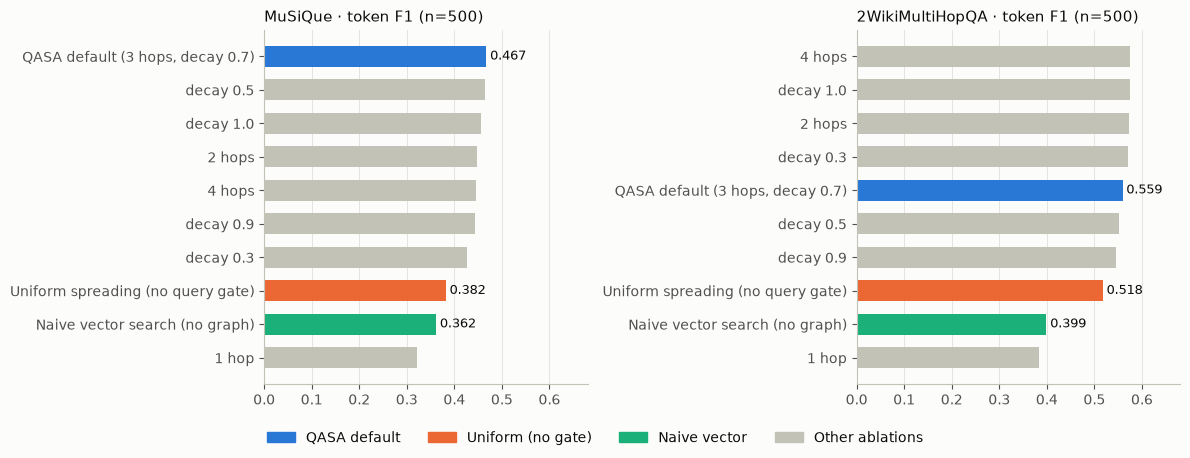

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, (key, name) in zip(axes, DATASETS.items()):
    df = ablation[key].iloc[::-1]
    colors = [ROLE_COLOR.get(c, NEUTRAL) for c in df.config]
    ax.barh([LABELS[c] for c in df.config], df.F1, color=colors, height=0.62)
    for y, (config, f1) in enumerate(zip(df.config, df.F1)):
        if config in ROLE_COLOR:
            ax.text(f1 + 0.008, y, f"{f1:.3f}", va="center", fontsize=9, color=INK)
    ax.set_title(f"{name} · token F1 (n=500)", loc="left", fontsize=11, color=INK)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 0.68)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE, AQUA, NEUTRAL)]
fig.legend(handles, ["QASA default", "Uniform (no gate)", "Naive vector", "Other ablations"],
           loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIGURES / "ablation_f1.png", dpi=160)
plt.show()

## 2 · Accuracy vs. context cost

Each dot is one configuration. The query gate keeps the activation frontier small, so QASA
reaches the best F1 with fewer prompt tokens than uniform spreading (a Pareto improvement that
does not depend on hardware, unlike wall-clock latency).

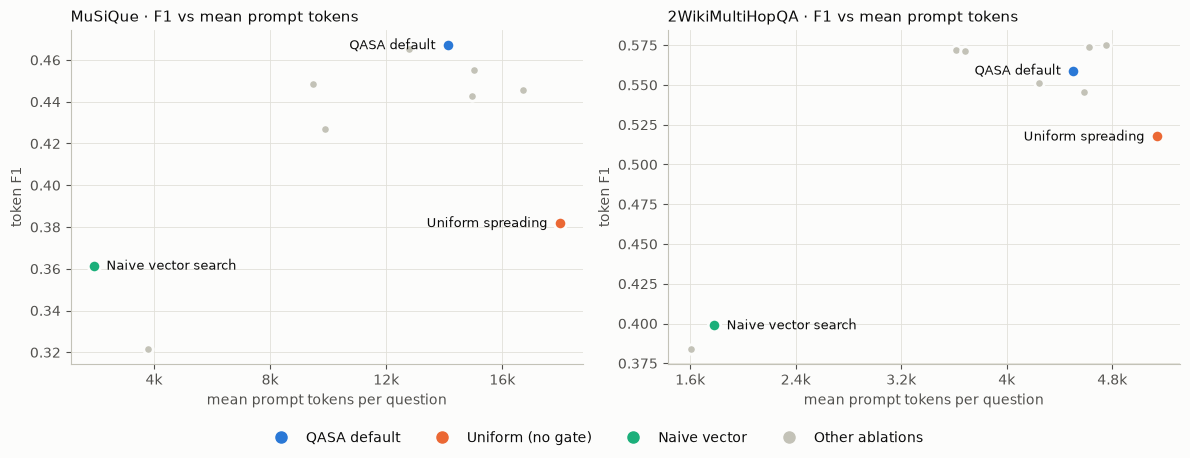

In [3]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (key, name) in zip(axes, DATASETS.items()):
    df = ablation[key]
    others = df[~df.config.isin(ROLE_COLOR)]
    ax.scatter(others.prompt_tokens, others.F1, s=46, color=NEUTRAL, edgecolor=SURFACE,
               linewidth=2, zorder=2)
    x_mid = (df.prompt_tokens.min() + df.prompt_tokens.max()) / 2
    for config, color in ROLE_COLOR.items():
        row = df[df.config == config].iloc[0]
        ax.scatter(row.prompt_tokens, row.F1, s=80, color=color, edgecolor=SURFACE,
                   linewidth=2, zorder=3)
        right_half = row.prompt_tokens > x_mid
        ax.annotate(LABELS[config].split(" (")[0], (row.prompt_tokens, row.F1),
                    textcoords="offset points", xytext=(-9 if right_half else 9, -3),
                    ha="right" if right_half else "left", fontsize=9, color=INK)
    ax.xaxis.set_major_locator(MaxNLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
    ax.set_title(f"{name} · F1 vs mean prompt tokens", loc="left", fontsize=11, color=INK)
    ax.set_xlabel("mean prompt tokens per question")
    ax.set_ylabel("token F1")
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=c)
           for c in (BLUE, ORANGE, AQUA, NEUTRAL)]
fig.legend(handles, ["QASA default", "Uniform (no gate)", "Naive vector", "Other ablations"],
           loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIGURES / "pareto_tokens_f1.png", dpi=160)
plt.show()

## 3 · Is the query gate significant? (full split, n=1000)

Same questions answered with and without the query-aware gate; paired bootstrap over questions.

In [4]:
rng = np.random.default_rng(0)
rows = []
for key, name in DATASETS.items():
    qa = pd.read_csv(RESEARCH / f"eval-results-{key}-query-aware.csv")
    uni = pd.read_csv(RESEARCH / f"eval-results-{key}-no-query-aware.csv")
    paired = qa.merge(uni, on="question_id", suffixes=("_qa", "_uni"))
    delta = (paired.f1_qa - paired.f1_uni).to_numpy()
    boot = [rng.choice(delta, len(delta)).mean() for _ in range(5000)]
    rows.append({
        "dataset": name, "n": len(paired),
        "F1 QASA": paired.f1_qa.mean(), "F1 uniform": paired.f1_uni.mean(),
        "ΔF1": delta.mean(), "95% CI low": np.percentile(boot, 2.5),
        "95% CI high": np.percentile(boot, 97.5),
        "LLM-acc QASA": paired.llm_accuracy_qa.mean(),
        "LLM-acc uniform": paired.llm_accuracy_uni.mean(),
        "prompt tok QASA": paired.prompt_tokens_qa.mean(),
        "prompt tok uniform": paired.prompt_tokens_uni.mean(),
    })
pd.DataFrame(rows).round(3)

,dataset,n,F1 QASA,F1 uniform,ΔF1,95% CI low,95% CI high,LLM-acc QASA,LLM-acc uniform,prompt tok QASA,prompt tok uniform
0,MuSiQue,1000,0.417,0.343,0.074,0.053,0.097,0.38,0.301,11837.535,17537.486
1,2WikiMultiHopQA,1000,0.550,0.514,0.035,0.014,0.058,0.54,0.505,4531.998,5248.657


## 4 · Where does it fail? (QASA default, n=1000 per dataset)

Seeds are always found (vector fallback), so failures are bucketed by what the answer looks like.

In [5]:
import re

ABSTAIN = re.compile(r"^(unknown|none|n/?a|not (found|specified|mentioned|available)|no )")
COMPARISON = re.compile(
    r"^(are|is|was|were|do|did)\b|\b(first|earlier|later|older|younger|longer|more|same)\b"
)

def bucket(row) -> str:
    prediction = str(row.prediction).strip().lower()
    if row.llm_accuracy == 1:
        return "right answer, EM/F1 miss (phrasing)"
    if prediction in ("", "nan") or ABSTAIN.search(prediction):
        return "abstained: answer not in retrieved subgraph"
    if COMPARISON.search(str(row.question).lower()):
        return "comparison question, wrong pick"
    return "wrong entity from retrieved subgraph"

for key, name in DATASETS.items():
    df = pd.read_csv(RESEARCH / f"eval-results-{key}-query-aware.csv")
    failed = df[df.f1 == 0].copy()
    failed["bucket"] = failed.apply(bucket, axis=1)
    print(f"{name}: {len(failed)} of {len(df)} questions have F1 = 0")
    counts = failed.bucket.value_counts()
    display((counts / len(failed)).round(2).rename("share of failures").to_frame())
    display(
        failed.groupby("bucket").head(1)[["bucket", "question", "ground_truth", "prediction"]]
        .reset_index(drop=True)
    )

MuSiQue: 495 of 1000 questions have F1 = 0


,share of failures
bucket,
wrong entity from retrieved subgraph,0.74
abstained: answer not in retrieved subgraph,0.18
"comparison question, wrong pick",0.06
"right answer, EM/F1 miss (phrasing)",0.02


,bucket,question,ground_truth,prediction
0,wrong entity from retrieved subgraph,What administrative territorial entity is the ...,Tamaulipas,nuevo laredo municipality
1,abstained: answer not in retrieved subgraph,Who is the child of the person who followed Ti...,Saint Sava,No information available.
2,"comparison question, wrong pick",What is the place of birth of the person who s...,Mount Laurel Township,Paulsdale
3,"right answer, EM/F1 miss (phrasing)",What company did the company that initiated a ...,Hewlett Packard,hewlett-packard


2WikiMultiHopQA: 380 of 1000 questions have F1 = 0


,share of failures
bucket,
wrong entity from retrieved subgraph,0.49
"comparison question, wrong pick",0.32
abstained: answer not in retrieved subgraph,0.13
"right answer, EM/F1 miss (phrasing)",0.05


,bucket,question,ground_truth,prediction
0,abstained: answer not in retrieved subgraph,"When did John V, Prince Of Anhalt-Zerbst's fat...",12 June 1516,Unknown
1,"comparison question, wrong pick","Which film has the director died first, Crimen...",The Working Class Goes To Heaven,Crimen a las tres
2,wrong entity from retrieved subgraph,Where was the director of film Thomas Jefferso...,Brooklyn,'ken burns'
3,"right answer, EM/F1 miss (phrasing)",Which country Prince Nikolaus Wilhelm Of Nassa...,German,Germany


## 5 · Local run of this app (qwen3.5:4b, Ollama)

`scripts/evaluate_local.py` asks the demo-graph questions through the real pipeline
(analyzer → retrieval → generation → validation → refinement) in two retrieval modes.
The graph here is ~500 documents extracted by a 4B model, so absolute numbers are
not comparable to the research runs above, only the QASA vs. naive gap is.

In [6]:
local = Path("results/local-eval.csv")
if local.exists():
    runs = pd.read_csv(local)
    summary = runs.groupby("mode").agg(
        n=("f1", "size"), EM=("em", "mean"), F1=("f1", "mean"),
        answered=("status", lambda s: (s == "answered").mean()),
        refined=("refined", "mean"), seconds=("seconds", "mean"),
    )
    display(summary.round(3))
else:
    print("results/local-eval.csv not found: run `uv run python scripts/evaluate_local.py`")

results/local-eval.csv not found: run `uv run python scripts/evaluate_local.py`
